# CLIP test

Checks that CLIP runs locally and gives sensible image features on a few of our images.

Same setup as Ojha et al. (CVPR 2023): ViT-L/14, 768-d projected image embedding, test-time preprocessing (center crop 224, CLIP mean/std, no augmentation).

Needs: `pip install torch torchvision transformers pillow pandas`

In [4]:
import sys
sys.path.insert(0, "../..")  # repo root, so `common` and `data` are importable

import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
from transformers import CLIPModel, CLIPProcessor

from common.device import get_device
from data import config

DATASET_DIR = config.dataset_dir()
MODEL_NAME = "openai/clip-vit-large-patch14"
device = get_device()

print("dataset:", DATASET_DIR, DATASET_DIR.exists())
print("torch:", torch.__version__, "device:", device)

dataset: /Users/tim/Developer/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c True
torch: 2.14.0 device: mps


## Load the model (downloads the weights the first time)

In [5]:
model = CLIPModel.from_pretrained(MODEL_NAME).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL_NAME)
print("embedding dim:", model.config.projection_dim)

# Like Ojha et al. at test time: center crop 224 from our 256 images, CLIP mean/std.
# (CLIPProcessor would instead resize the short side to 224 first, shrinking the whole image.)
preprocess = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=processor.image_processor.image_mean, std=processor.image_processor.image_std),
])

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

embedding dim: 768


## One image

meta_train/ADM/fake/d18ffce5c8a57a403518fd99db546fba.jpg ADM fake (256, 256)


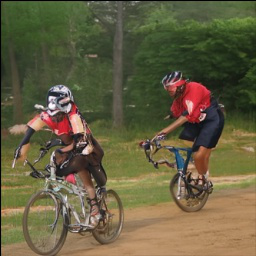

In [19]:
manifest = pd.read_csv(DATASET_DIR / config.MANIFEST_FILE)
row = manifest.iloc[160]
img = Image.open(DATASET_DIR / row.file).convert("RGB")
print(row.file, row.generator, config.LABEL_NAMES[row.label], img.size)
img

In [20]:
pixel_values = preprocess(img).unsqueeze(0).to(device)
with torch.no_grad():
    feats = model.get_image_features(pixel_values=pixel_values).pooler_output
feats = feats / feats.norm(dim=-1, keepdim=True)
print(feats.shape, feats.norm().item())
print(feats)

torch.Size([1, 768]) 0.9999999403953552
tensor([[ 4.0570e-02, -4.1525e-02, -1.5655e-02, -1.6719e-02, -7.8053e-03,
          4.3898e-02, -1.6772e-02,  1.5149e-03,  4.3553e-03, -2.3258e-03,
         -8.8479e-03, -3.1467e-02,  4.3009e-03,  8.0053e-03,  1.2894e-02,
         -3.9094e-02,  1.2845e-02, -4.7052e-02, -2.0827e-02,  4.2449e-03,
          5.2351e-03,  1.5813e-03,  2.0071e-02,  5.2667e-03, -6.8815e-02,
          1.4306e-02, -9.1648e-03, -4.4154e-02, -1.0865e-02, -1.2619e-02,
          2.0828e-02,  1.1713e-03, -2.2484e-02, -7.6861e-03,  3.5434e-02,
          3.0955e-03, -1.6945e-02,  1.0452e-02, -2.4179e-03, -7.9111e-03,
          4.6639e-02,  7.5398e-03, -3.8069e-02, -2.7910e-02, -6.0562e-03,
         -7.5648e-03,  1.9120e-02, -1.2669e-02, -1.0167e-03, -1.2930e-02,
         -1.4106e-02,  2.1888e-02, -1.7421e-02,  1.5994e-02,  7.6885e-03,
          3.3797e-02,  2.0740e-02, -3.1101e-03, -3.4066e-02, -1.7094e-03,
          2.4428e-02, -5.3366e-02, -3.5866e-02,  3.4136e-02,  2.3476e-02

## A small batch: one real and one fake image per generator

In [21]:
sample = manifest.groupby(["generator", "label"]).head(1).sort_values(["generator", "label"]).reset_index(drop=True)
images = [Image.open(DATASET_DIR / f).convert("RGB") for f in sample.file]

pixel_values = torch.stack([preprocess(im) for im in images]).to(device)
with torch.no_grad():
    batch_feats = model.get_image_features(pixel_values=pixel_values).pooler_output
batch_feats = batch_feats / batch_feats.norm(dim=-1, keepdim=True)
print(batch_feats.shape)

torch.Size([16, 768])


## Runtime estimate for the whole dataset

A few hundred images are enough: after a warm-up batch the time per image is stable, so a few thousand wouldn't
change the estimate. Two parts are timed separately:

1. **Loading**: open the JPEG + `preprocess`, per image on the CPU
2. **Model**: forward passes on already loaded images, for several batch sizes (does batching help?)

In [23]:
import time

N_TIMING = 512
BATCH_SIZES = [1, 8, 32, 64, 128]

timing_files = manifest.file.sample(N_TIMING, random_state=config.SEED).tolist()

start = time.time()
timing_pixels = torch.stack([preprocess(Image.open(DATASET_DIR / f).convert("RGB")) for f in timing_files])
load_per_image = (time.time() - start) / N_TIMING
print(f"loading: {1000 * load_per_image:.1f} ms/image")

loading: 3.0 ms/image


In [24]:
def sync():
    if device == "mps":
        torch.mps.synchronize()
    elif device == "cuda":
        torch.cuda.synchronize()

model_per_image = {}
with torch.no_grad():
    for batch_size in BATCH_SIZES:
        model.get_image_features(pixel_values=timing_pixels[:batch_size].to(device))  # warm-up
        sync()
        start = time.time()
        for i in range(0, N_TIMING, batch_size):
            model.get_image_features(pixel_values=timing_pixels[i:i + batch_size].to(device))
        sync()
        model_per_image[batch_size] = (time.time() - start) / N_TIMING
        print(f"batch size {batch_size:4d}: {1000 * model_per_image[batch_size]:6.1f} ms/image, "
              f"{1 / model_per_image[batch_size]:6.1f} images/s")   

batch size    1:   61.0 ms/image,   16.4 images/s
batch size    8:   49.9 ms/image,   20.0 images/s
batch size   32:   50.9 ms/image,   19.6 images/s
batch size   64:   49.4 ms/image,   20.3 images/s
batch size  128:   53.7 ms/image,   18.6 images/s


In [1]:
best_batch_size = min(model_per_image, key=model_per_image.get)
n_total = len(manifest)

# Loading one image after the other adds up with the model time. With DataLoader workers loading the next
# batches during the forward pass, only the slower of the two counts.
sequential = n_total * (load_per_image + model_per_image[best_batch_size])
overlapped = n_total * max(load_per_image / 4, model_per_image[best_batch_size])  # 4 workers

print(f"{n_total} images, batch size {best_batch_size}")
print(f"  loading in the same process:  {sequential / 3600:.1f} h")
print(f"  loading in 4 workers:         {overlapped / 3600:.1f} h")

NameError: name 'model_per_image' is not defined